In [28]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [30]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import tqdm
from time import time_ns

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 8
print(f"Currently using {DEVICE}")

Currently using cpu


In [31]:
torch.manual_seed(0)

In [32]:
%autoreload

In [33]:
from src.data_import import *
train_loader, test_loader = load_olivetti(batch_size=BATCH_SIZE, shuffle=True)

label: 27
shape: torch.Size([8, 1, 64, 64])


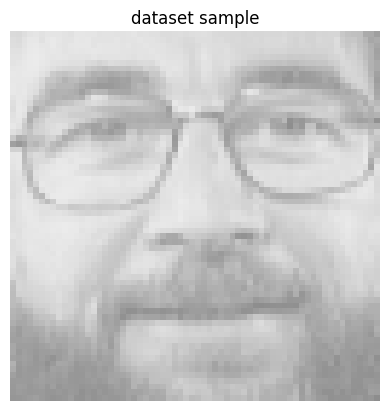

In [34]:
from src.plot import show_single_sample, show_grid

x_real, _ = next(iter(train_loader))
show_single_sample(x_real[0], "dataset sample", cmap="gray")
#print label
print("label:", _[0].item())
print("shape:", x_real.shape)

In [35]:
n_heads = 3
IMAGE_SHAPE = (1, 64, 64)

In [36]:
from src.model import EBM

params = torch.load("./models/olivetti/EBM_5_epochs_(1, 64, 64)_shape_3_heads_1793110626790547477.pth")
model = EBM(image_shape=(1, 64, 64), n_heads=3)
model.load_state_dict(params)
model.to(DEVICE)

EBM(
  (heads): ModuleList(
    (0-2): 3 x EnergyHead(
      (conv): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): GELU(approximate='none')
        (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (3): GELU(approximate='none')
        (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (5): GELU(approximate='none')
      )
      (fc): Sequential(
        (0): Linear(in_features=16384, out_features=49, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=49, out_features=1, bias=True)
      )
    )
  )
)

In [37]:
from src.sampler import ReplaySampler

sampler = ReplaySampler(model=model, img_shape=IMAGE_SHAPE, buffer_size=600, noise_fraction=0.05, device=DEVICE)

EBM DIAGNOSTICS

[1] Energy on real data


  Train  →  mean=-0.0256,  std=0.0236
  Test   →  mean=-0.0276,  std=0.0223
  |E_test - E_train| = 0.0020  (ok)

[2] Energy on fake data (Langevin samples)
  Fake   →  mean=-0.0584,  std=0.0013
  Gap (E_real_train - E_fake) = 0.0328  (WARNING: gap inverted)

[3] Energy on pure noise
  Noise  →  mean=3.1664,  std=0.0656
  Gap (E_real_train - E_noise) = -3.1920  (ok)

[4] Per-head energy (on train batch)
  Head 0  →  mean=0.1622,  std=0.0177
  Head 1  →  mean=0.1422,  std=0.0212
  Head 2  →  mean=-0.3234,  std=0.0216
  Max off-diagonal correlation: 0.8572  (WARNING: heads are correlated)

[5] Replay buffer
  Buffer size: 8 / 600
  Buffer samples  →  mean=0.4469,  std=0.1796,  min=-0.6411,  max=1.0000

[6] Visual samples (Langevin from noise)


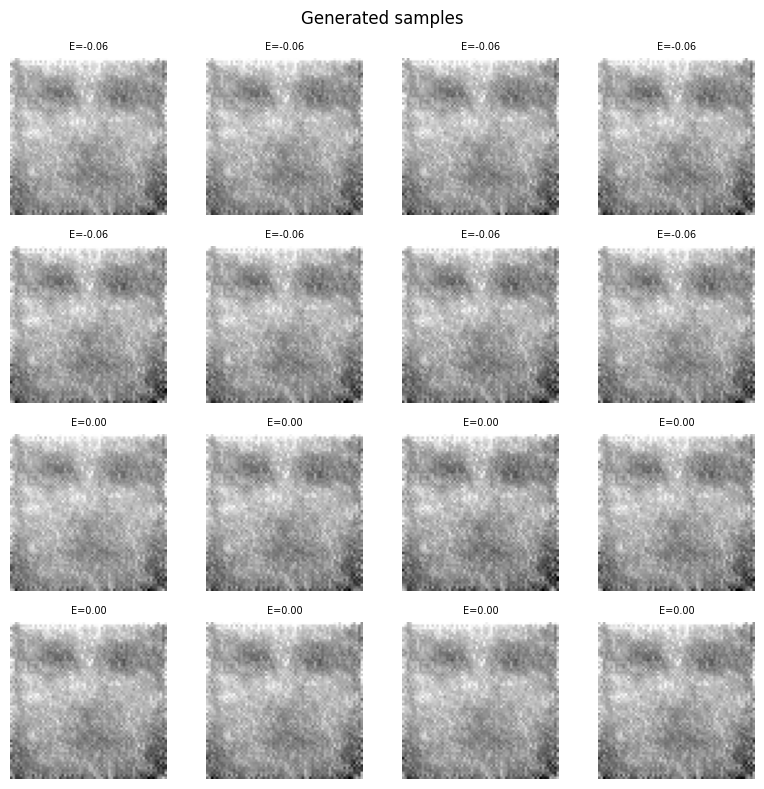


DONE


In [43]:
from src.diagnostic import diagnose

diagnose(model, sampler, IMAGE_SHAPE, train_loader, test_loader, device=DEVICE, n_samples=16)

In [44]:
model.to(DEVICE)

EBM(
  (heads): ModuleList(
    (0-2): 3 x EnergyHead(
      (conv): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): GELU(approximate='none')
        (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (3): GELU(approximate='none')
        (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (5): GELU(approximate='none')
      )
      (fc): Sequential(
        (0): Linear(in_features=16384, out_features=49, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=49, out_features=1, bias=True)
      )
    )
  )
)

In [45]:
model.to(DEVICE)
samples = sampler.generate(10, steps=200, step_size=1.0, noise_std=0.005)

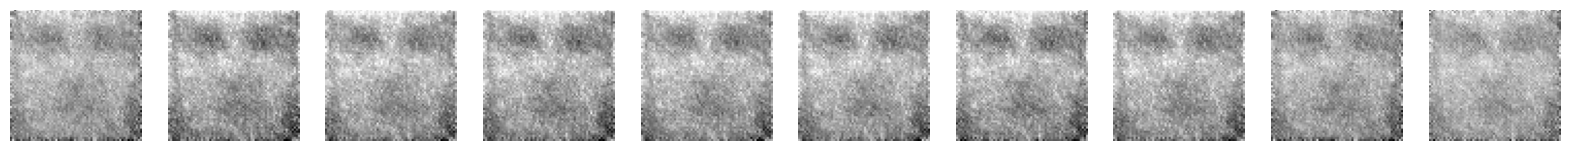

In [46]:
show_grid(samples, 10, cmap="gray")

In [47]:
from src.plot import visualize_head_gradients, visualize_head_abs_gradients

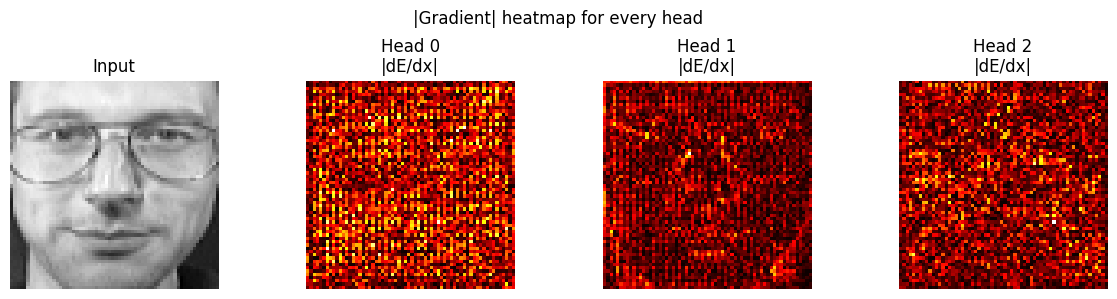

In [48]:
it = iter(test_loader)

for _ in range(0):
    it.__next__()
x0 = it.__next__()[0]

visualize_head_abs_gradients(model.to(DEVICE), x0, DEVICE)


In [49]:
from src.gradient_inspect import synthetize_image_from_head, synthetize_image

model.to("cpu")

class Combined(nn.Module):

    def __init__(self, m1, m2=None):
        super().__init__()
        self.m1 = m1
        self.m2 = m2

    def forward(self, x):
        if self.m2 is None:
            return self.m1(x)

        return self.m1(x) + self.m2(x)

img0, _ = synthetize_image_from_head(Combined(model.heads[0]), n_images=1, img_dimension=IMAGE_SHAPE[-1], steps=1_000)
img1, _ = synthetize_image_from_head(Combined(model.heads[1]), n_images=1, img_dimension=IMAGE_SHAPE[-1], steps=1_000)
img2, _ = synthetize_image_from_head(Combined(model.heads[2]), n_images=1, img_dimension=IMAGE_SHAPE[-1], steps=1_000)
img01, _ = synthetize_image_from_head(Combined(model.heads[0], model.heads[1]), n_images=1, img_dimension=IMAGE_SHAPE[-1], steps=1_000)
img02, _ = synthetize_image_from_head(Combined(model.heads[0], model.heads[2]), n_images=1, img_dimension=IMAGE_SHAPE[-1], steps=1_000)
img12, _ = synthetize_image_from_head(Combined(model.heads[1], model.heads[2]), n_images=1, img_dimension=IMAGE_SHAPE[-1], steps=1_000)

model.to(DEVICE)

EBM(
  (heads): ModuleList(
    (0-2): 3 x EnergyHead(
      (conv): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): GELU(approximate='none')
        (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (3): GELU(approximate='none')
        (4): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
        (5): GELU(approximate='none')
      )
      (fc): Sequential(
        (0): Linear(in_features=16384, out_features=49, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=49, out_features=1, bias=True)
      )
    )
  )
)

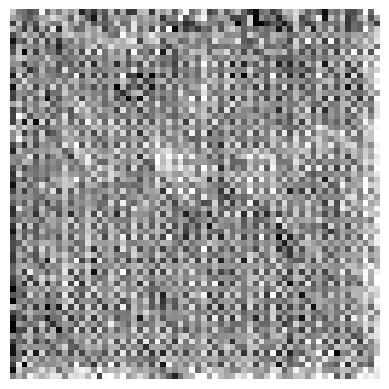

In [50]:
show_single_sample(img0, cmap="gray")

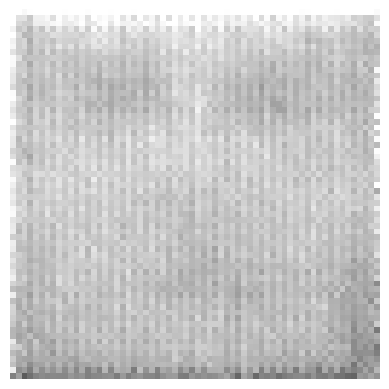

In [51]:
show_single_sample(img1, cmap="gray")

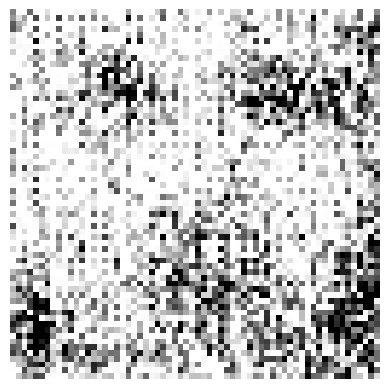

In [52]:
show_single_sample(img2, cmap="gray")

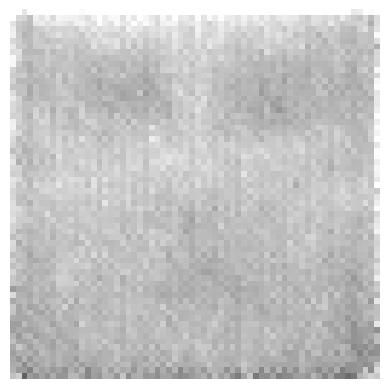

In [53]:
show_single_sample(img01, cmap="gray")

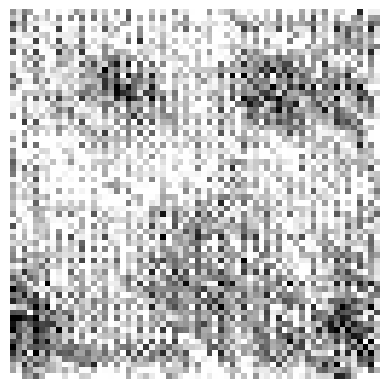

In [54]:
show_single_sample(img02, cmap="gray")

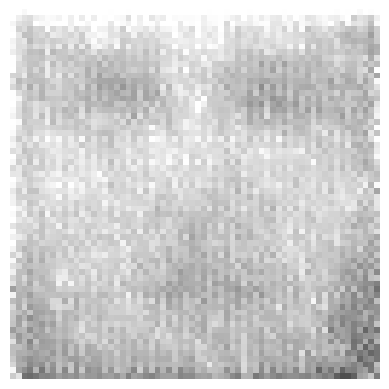

In [55]:
show_single_sample(img12, cmap="gray")

In [ ]:
img, _ = synthetize_image(model.to("cpu"), img_dimension=IMAGE_SHAPE[-1], steps=5_000, step_size=1.0)
show_single_sample(img, cmap="gray")